

### Problem specification



Let $y_{i,t} \sim D(\mu_{i,t}, \sigma_{i,t})$ be the return of an asset $i$ at time $t$ and let $w_{i,t}$  be the weight of an asset in a portfolio.  We could describe our portfolio by its MLE estimates of mean and variances, i.e.,

$$
\mu_{p,t} = \sum_{i}^{N}w_{i,t}\mu_{i,t} = \mathbf{w}_{t}^{T}\mathbf{\mu}_{t}
$$
$$
\sigma_{p,t} = \sum_{i}^{N}\sum_{j}^{N}w_{i,t}w_{j,t}\sigma_{i,j,t} = \mathbf{w}_{t}^{T}\mathbf{\Sigma}_{t}\mathbf{w}_{t}
$$

Assume also that the asset returns are governed by some linear factors $x_{t,j}$ and a random noise term $\epsilon_{i,t+1}$:

$$
y_{i,t+1} = \sum_{j}^{M+1}\beta_{j,i}x_{t,j} + \epsilon_{i,t+1}
$$

Written more compactly:

$$
\mathbf{Y} = \mathbf{X}\mathbf{\beta} + \mathbf{E}
$$

where,

- $\mathbf{Y}$ is a $(T,N)$ matrix of $T$ monthly returns of $N$ assets
- $\mathbf{X}$ is a $(T,M)$ matrix of $T$ monthly factors of $M$ number of factors
- $\beta$ is a $(M,N)$ matrix of time-invariant parameters explaining the effect of $M$ factors on $N$ assets. We will use interchangebly the terms 'factor loadings' and 'betas'.
- $\mathbf{E}$ is a $(T,N)$ matrix of $T$ monthly error terms of $N$ assets, i.e., $E \sim N(0,\Sigma_{\epsilon})$

Using such factor model, we could estimate the mean and the variance as:

$$
\mathbb{E}_{t+1|t}[\mathbf{Y}] = \mathbf{\mu}_{t+1} = \mathbf{x}_{t}\mathbf{\beta}
$$
$$
\mathbb{V}_{t+1|t}[\mathbf{Y}] = \mathbf{\Sigma}_{t+1} = \beta\Sigma_{x}\beta^{T} + \Sigma_{\epsilon}
$$





This is a time-series factor model, i.e., the factor loading are akin to estimating correlations through time (in a univarite setting, $\hat{\beta} = \frac{\text{Cov}(y_{i,t}, x_{t})}{\text{Var}(x_{t})}$, while in multivariate the partial effect is adjusted by the interdependency of the predictors).

Our goal is to optimize an arbitrary metric that depends on the distributional moment of $\mathbf{Y}$. This could be anything, but for simplicity, let's start with the Sharpe ratio.

$$
SR_{t+1} = \frac{\mathbf{w}_{t}\mathbb{E}_{t+1|t}[\mathbf{Y}] - rf_{t}}{\mathbf{w}_{t}\mathbb{V}_{t+1|t}[\mathbf{Y}]\mathbf{w}_{t}^{T}} = \frac{\mathbf{w}_{t}\mathbf{\mu}_{t+1} - rf_{t}}{\mathbf{w}_{t}\mathbf{\Sigma}_{t+1}\mathbf{w}_{t}^{T}}
$$




### Factors

##### Principal Components

Firstly, we assume that the common factors are principal components derived from the $\mathbf{Y}$ matrix. There's a few ways of doing this.

- Perform a SVD on the $\mathbf{Y}$ matrix
- Perform a PCA on the empirical covariance matrix, i.e., $\text{cov}(\mathbf{Y})$, i.e., $(\mathbf{Y}-\bar{\mathbf{Y}})^{T}(\mathbf{Y}-\bar{\mathbf{Y}})/(T-1)$
- Perform a SVD on the $\mathbf{Y}-\mathbf{\bar{Y}}$, which is the equivalent as the one above

All three are supported by the library. Note that in the last case, the empirical covariance can be retrieved:

$$
\mathbf{\tilde{Y}} = \mathbf{Y}-\mathbf{\bar{Y}}
$$
$$
\mathbf{\tilde{Y}} = \mathbf{U}\mathbf{S}\mathbf{V^{T}}
$$
$$
\mathbf{L} = \text{diag}(\mathbf{S}) | \mathbf{0}
$$
$$
\text{cov}(\mathbf{Y}) = \mathbf{V^{T}}\mathbf{L}\mathbf{V} / (T-1)
$$

where, $\mathbf{L}$ is constructed by concatenating the singular values with a zero matrix such that the dimesions match (recall that otherwise $\mathbf{S}$ is rectangular)

There is one issue, however. In a time-series regression, we cannot perform the PCA on the entire matrix beforehand since we will therefore introduce information leakage. This occurs if we estimate $\mathbf{E}[y_{i,t}]=\beta_{j}x_{j,t}$ while $x_{j,t}$ is a principal component produced by decomposoing the \textit{entire} $\mathbf{Y}$ matrix (which includes $y_{t+1}, y_{t+2}, ...$). Hence, we need to perform a rolling PCA.

In this notebook, we will try to circumvent this issue by using a rolling PCA and we will further test the assumption of weakly stationary factors.






In [1]:
assets = ['CHRW.OQ', 'MCD.N', 'BAX.N', 'AMAT.OQ', 'UPS.N']

In [2]:
import os
import numpy as np
import datetime as dt
from examples.example_executor_mvp_v3 import Executor
import matplotlib.pyplot as plt
import pandas as pd
from models.unsupervised.pca import RollingPcaHandler, PcaHandler
from statsmodels.tsa.stattools import adfuller
from statsmodels.regression.linear_model import OLS

In [3]:
START_DATE = '2005-12-31'

PATH_DATA = r'C:\Users\serge\OneDrive\portfolio_management\data\csv'
PATH_API_KEYS = r'C:\Users\serge\OneDrive\reuters\apikeys.csv'
PATH_SAVE_PLOTS = os.path.join(r'results\figures')
PATH_CONFIG = r'C:\Users\serge\IdeaProjects\portfolio_management\notebooks\examples\config_example.yaml'

In [4]:
END_DATE = '2024-04-21'
executor = Executor(START_DATE, END_DATE, PATH_DATA, PATH_API_KEYS, PATH_CONFIG)

executor._load_data()
executor._preprocess()

2025-01-12 23:08:55,546 P[14572] [MainThread 12432] Error: no proxy address identified.
Check if Eikon Desktop or Eikon API Proxy is running.
2025-01-12 23:08:55,546 P[14572] [MainThread 12432] Error on handshake url http://127.0.0.1:None/api/handshake : InvalidURL("Invalid port: 'None'")
2025-01-12 23:08:55,546 P[14572] [MainThread 12432] Error on handshake url http://127.0.0.1:None/api/handshake : InvalidURL("Invalid port: 'None'")
2025-01-12 23:08:55,551 P[14572] [MainThread 12432] Port number was not identified, cannot send any request


[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\WM.N.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\REG.OQ.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\BIO.N.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\IVZ.N.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\EXPE.OQ.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\GEN.OQ.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\DAY.N.csv'
[Errno 2] No such file or directory: 'C:\\Users\\serge\\OneDrive\\portfolio_management\\data\\csv\\prices\\GRMN.N.csv'
[Errno 2] No such file or directory: 'C:\\Users\\ser

In [5]:
Y = executor.returns
Y.shape

(650, 276)

In [6]:
Y.head()

,POOL.OQ,CHRW.OQ,AJG.N,CNP.N,BA.N,WY.N,MCD.N,HD.N,SPG.N,HBAN.OQ,...,ACGL.OQ,NDSN.OQ,AMT.N,CAG.N,TFX.N,WAT.N,INCY.OQ,LRCX.OQ,IDXX.OQ,PPG.N
2006-01-12,-0.004102,-0.023050,-0.003377,-0.000821,-0.010105,0.008291,0.036367,0.030450,0.042593,0.000830,...,0.000268,0.081789,0.063717,-0.007177,-0.027333,0.014804,0.028701,0.070440,0.031001,0.007250
2006-01-24,0.045462,0.067258,-0.048988,-0.003903,-0.030383,0.004961,0.029192,-0.051434,-0.000699,-0.046379,...,-0.029521,0.007678,0.015190,0.033881,-0.002384,0.106398,-0.078291,0.114364,-0.032920,0.003786
2006-02-02,0.023674,0.014389,-0.052877,-0.017196,0.057136,-0.006642,-0.012080,-0.013047,0.011635,-0.017835,...,0.017815,-0.015894,0.036943,-0.018542,-0.013771,-0.057936,0.063802,0.039048,0.057657,-0.013537
2006-02-13,0.006772,0.047638,0.012147,0.001498,0.004850,0.024403,0.024494,-0.007380,-0.030833,0.001779,...,-0.031166,0.041425,-0.008365,-0.014933,-0.000060,0.012574,-0.053794,0.008666,-0.013049,0.003278
2006-02-23,0.089376,0.059286,0.033788,0.030720,0.023663,-0.005217,-0.022262,0.045411,0.047163,0.046180,...,0.059767,0.012276,0.030768,0.007906,0.014698,0.060964,0.059424,-0.068775,0.025963,0.019033


The PCA has infinite number of solutions, however, when the solutions are constrained s.t. the eigenvectors have length 1 (standardized eigenvectors), there are only two solutions. One is the negatively/positively scaled version of the others. Hence, we observe jumps in the time-series. By simply flipping the sign whenever this happens, we arrive at a more stable time-series of principal component. We will perform three rollings PCAs: ordinary, ordinary with sign flip trick, and R2-robust. The latter two should take care of the eigenvector sign flip.

In [7]:
n_components = 6
pca = RollingPcaHandler(PcaHandler, data=Y, n_components=n_components, demean=True, rolling_window=200)
X_pca_flip = pca.estimate(method='ordinary_scaled')
X_pca = pca.estimate(method='ordinary')
X_r2 = pca.estimate(method='r2pca')



Estimating PCA for 2011-08-10
Estimating PCA for 2011-08-19
Estimating PCA for 2011-08-30
Estimating PCA for 2011-09-09
Estimating PCA for 2011-09-20
Estimating PCA for 2011-09-29
Estimating PCA for 2011-10-19
Estimating PCA for 2011-10-28
Estimating PCA for 2011-11-08
Estimating PCA for 2011-11-17
Estimating PCA for 2011-11-29
Estimating PCA for 2011-12-08
Estimating PCA for 2011-12-19
Estimating PCA for 2011-12-29
Estimating PCA for 2012-01-10
Estimating PCA for 2012-01-20
Estimating PCA for 2012-01-31
Estimating PCA for 2012-02-09
Estimating PCA for 2012-02-21
Estimating PCA for 2012-03-01
Estimating PCA for 2012-03-12
Estimating PCA for 2012-03-21
Estimating PCA for 2012-03-30
Estimating PCA for 2012-04-11
Estimating PCA for 2012-04-20
Estimating PCA for 2012-05-01
Estimating PCA for 2012-05-10
Estimating PCA for 2012-05-21
Estimating PCA for 2012-05-31
Estimating PCA for 2012-06-11
Estimating PCA for 2012-06-20
Estimating PCA for 2012-06-29
Estimating PCA for 2012-07-11
Estimating

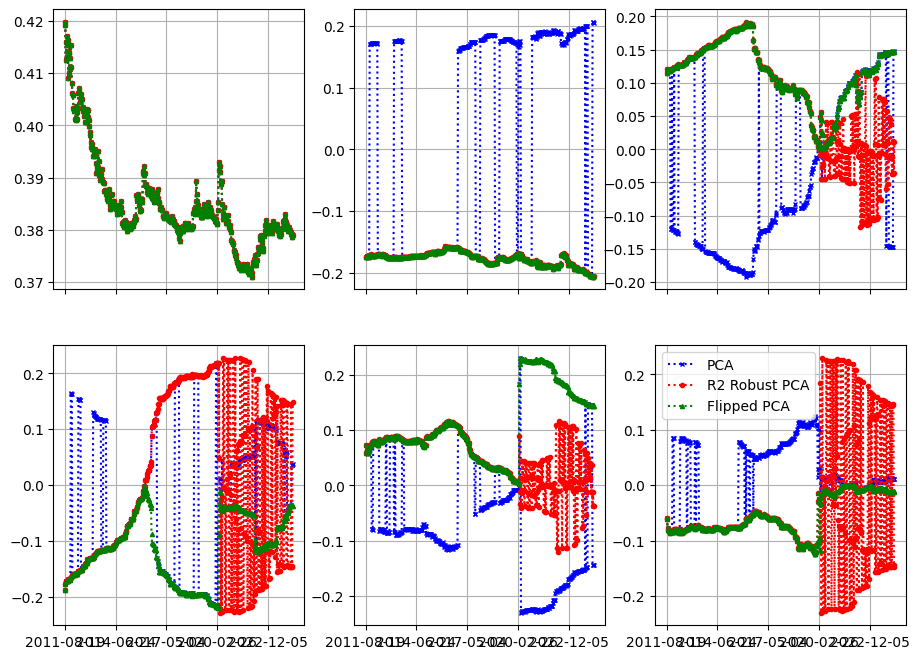

In [8]:
fig, axs = plt.subplots(2,3,figsize=(11,8), sharex=True)

for i, ax in enumerate(axs.flatten()):


    X_pca.iloc[:,i].plot(ax=ax, label='PCA', marker='x', ls=':', c='blue', markersize=3)
    X_r2.iloc[:,i].plot(ax=ax, label='R2 Robust PCA', marker='o', ls=':', c='red', markersize=3)
    X_pca_flip.iloc[:,i].plot(ax=ax, label='Flipped PCA', marker='^', ls=':', c='green', markersize=3)
    ax.grid(True)
ax.legend()

plt.show()


It seems that a simple flip of the sign works the best.


We also would like for our factors to be weakly stationary, as this is one of the main assumptions of a linear factor model. We are going to have a look at the first component. The first component is non stationary. Differencing, however, improves this.


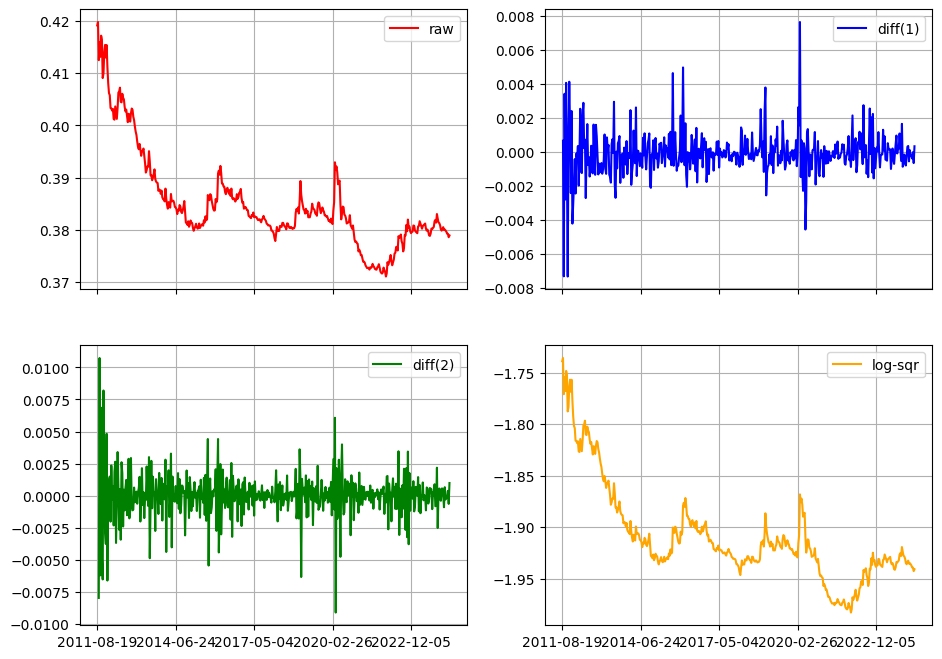

In [9]:
PCs = X_pca_flip
which = 0

fig, ax = plt.subplots(2,2, sharex=True, sharey=False, figsize=(11,8))
PC = PCs.iloc[:,which]
dPC = PC - PC.shift(1)
d2PC = dPC - dPC.shift(1)
PC.plot(ax=ax[0,0], label='raw', c='red')
dPC.plot(ax=ax[0,1], label='diff(1)', c='blue')
d2PC.plot(ax=ax[1,0], label='diff(2)', c='green')
np.log(PC ** 2).plot(ax=ax[1,1], label='log-sqr', c='orange')
for _ax in ax.flatten():
    _ax.legend()
    _ax.grid(True)
plt.show()

It seems that 2-order differencing works the best. We can test this by running a Dickey-Fuller test. We can reject the existence of a unit root.

In [10]:
for i in range(6):

    PC = PCs.iloc[:,i]
    dPC = PC - PC.shift(1)
    d2PC = dPC - dPC.shift(1)

    _, pval, _, _, _, _ = adfuller(PCs.iloc[:,i].dropna(), regression='n')
    print(f'p-value, component {i} (raw): {pval}')
    _, pval, _, _, _, _ = adfuller(d2PC.dropna(),  regression='n')
    print(f'p-value, component {i} (2-order difference): {pval}')

p-value, component 0 (raw): 0.10315454797363277
p-value, component 0 (2-order difference): 2.30820993349295e-19
p-value, component 1 (raw): 0.9044185351675318
p-value, component 1 (2-order difference): 1.032511324443329e-16
p-value, component 2 (raw): 0.6190533008155725
p-value, component 2 (2-order difference): 1.497091568302888e-13
p-value, component 3 (raw): 0.15039986178516584
p-value, component 3 (2-order difference): 4.9279641735409254e-20
p-value, component 4 (raw): 0.44923934849325664
p-value, component 4 (2-order difference): 8.606766188241787e-17
p-value, component 5 (raw): 0.1395268272311943
p-value, component 5 (2-order difference): 8.86076726842351e-22


We are now ready to test the factor loading stability. This tests the assumption of time-invarient beta and if we prove it wrong, we might have to consider assuming a functional form for our parameters. We will start by estimating ordinary least squares regressions and add additional complexity as we move on. We will additionally fit two models, the first will be using our rolling PCA which avoids the information leakage in time, while the latter will have a regular PCA, with information leakage.

In [11]:
dPCs = (PCs - PCs.shift(1))
d2PCs = (dPCs - dPCs.shift(1))

In [12]:
Y.head()
data = Y.join(dPCs)

In [13]:
data.dropna(inplace=True)

y = data.iloc[:,0].to_numpy()
X = data.loc[:, np.arange(n_components)].to_numpy()

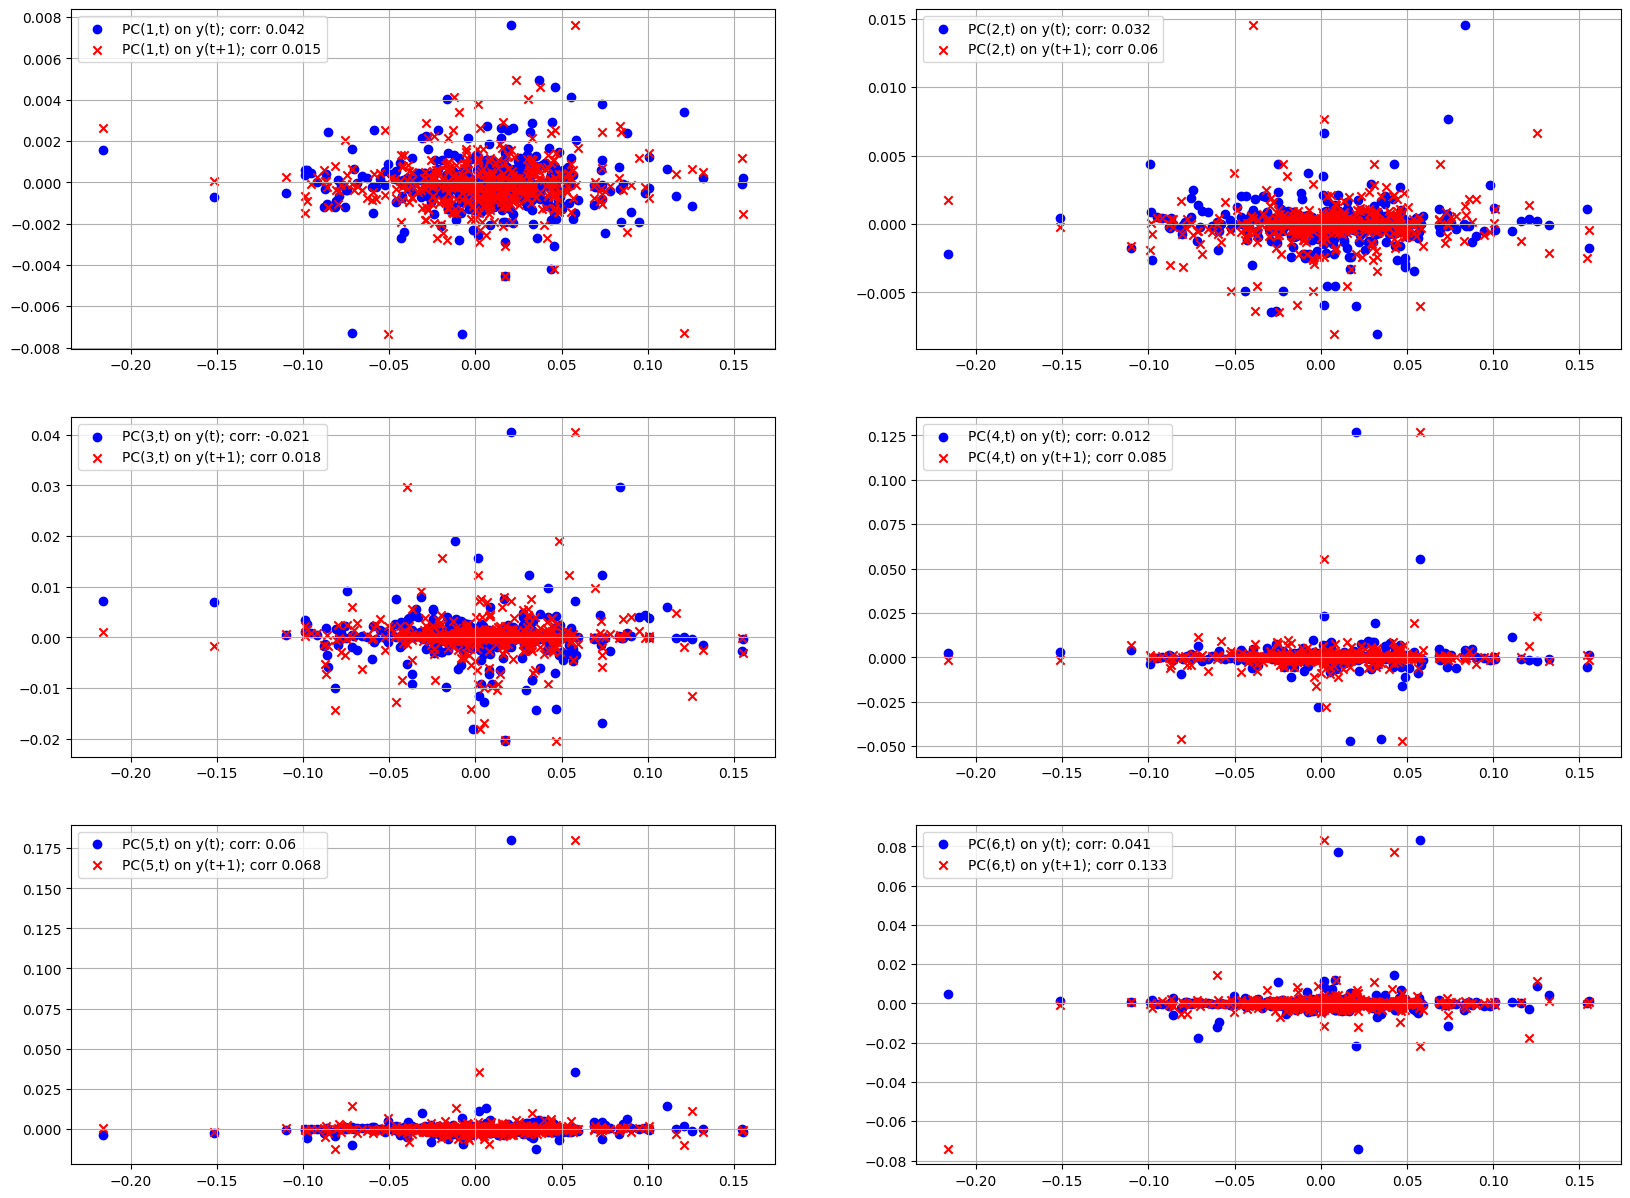

In [14]:
fig, axs = plt.subplots(3,2,figsize=(20,15))
for i, ax in enumerate(axs.flatten()):

    _corr = np.round(np.corrcoef(y, X[:,i])[0,1],3)
    ax.scatter(y, X[:,i], label=f'PC({i+1},t) on y(t); corr: {_corr}', color='blue', marker='o')
    _corr = np.round(np.corrcoef(y[1:], X[:-1,i])[0,1],3)
    ax.scatter(y[1:], X[:-1,i], label=f'PC({i+1},t) on y(t+1); corr {_corr}', color='red', marker='x')

    ax.grid(True)
    ax.legend()
    ax.grid(True)


plt.show()

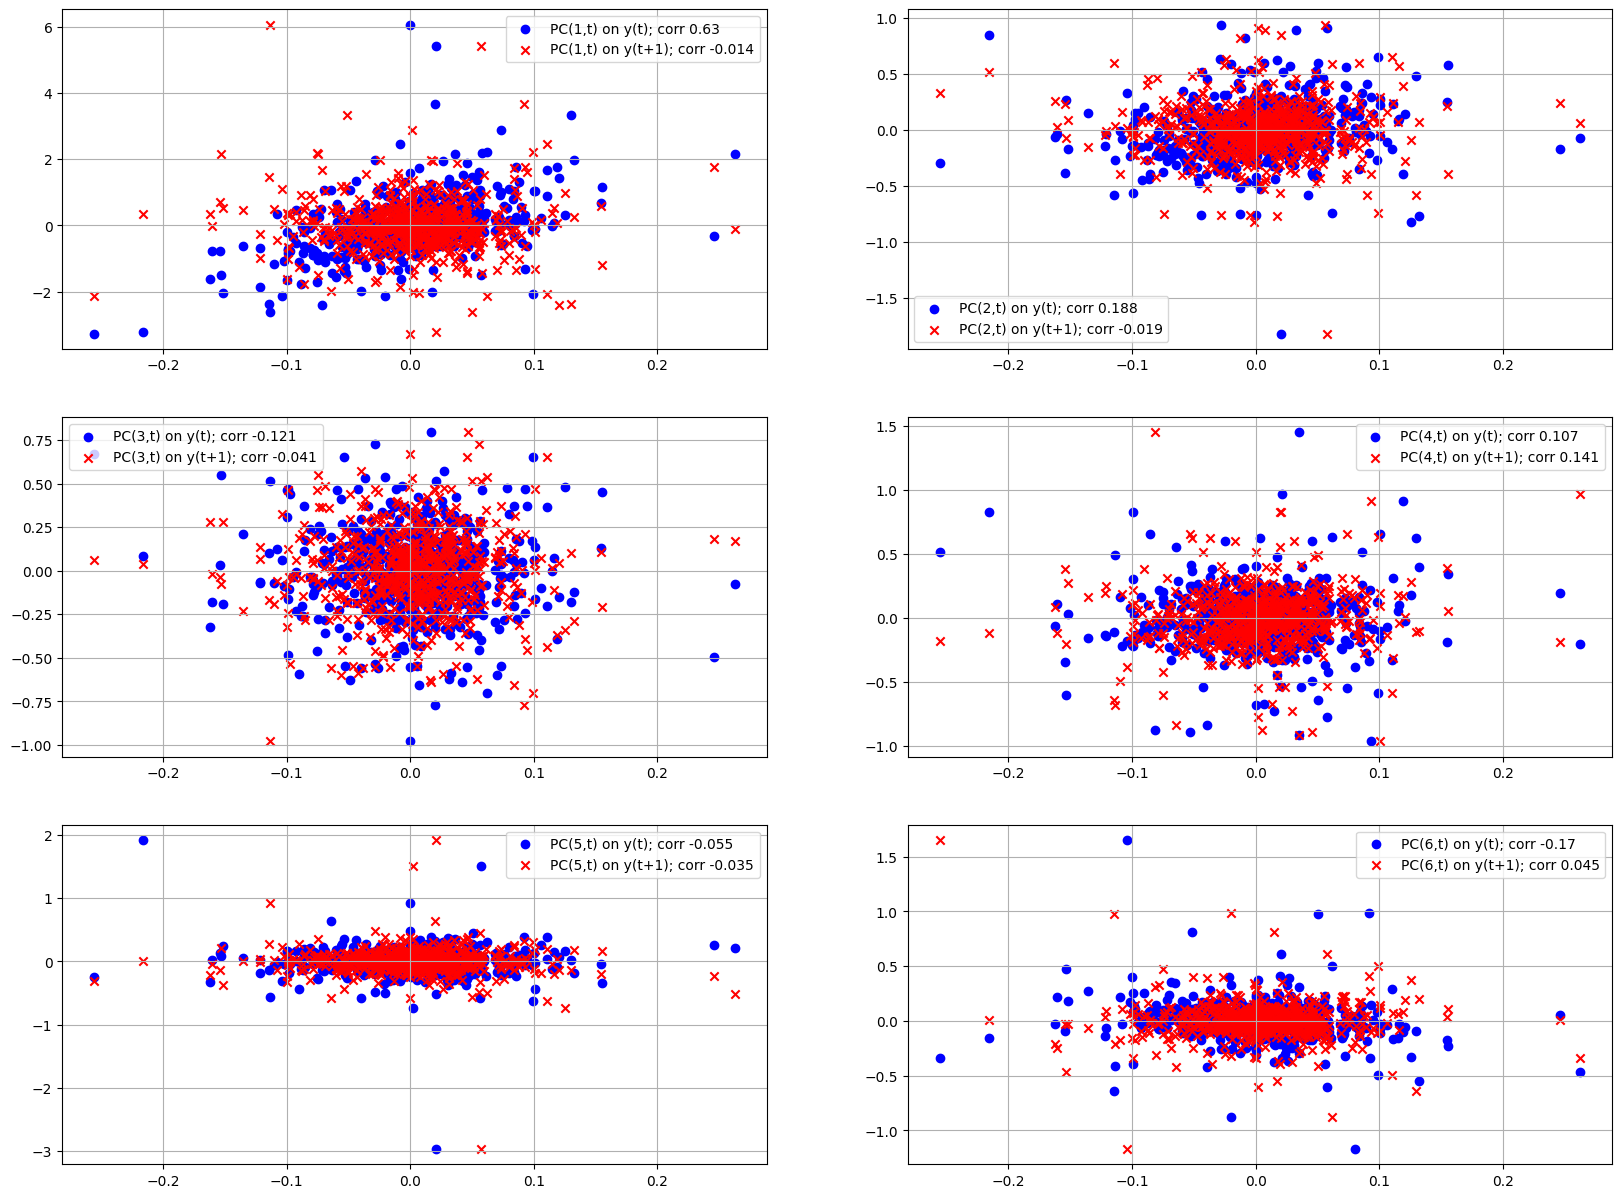

In [15]:
fig, axs = plt.subplots(3,2,figsize=(20,15))
X_leakage = PcaHandler(X=Y).components(n_components)
dX_leakage = X_leakage[1:,:] - X_leakage[:-1,:]
for i, ax in enumerate(axs.flatten()):

    _corr = np.round(np.corrcoef(Y.iloc[:,0], X_leakage[:,i])[0,1],3)
    ax.scatter(Y.iloc[1:,0], dX_leakage[:,i], label=f'PC({i+1},t) on y(t); corr {_corr}', color='blue', marker='o')
    _corr = np.round(np.corrcoef(Y.iloc[1:,0], X_leakage[:-1,i])[0,1],3)
    ax.scatter(Y.iloc[2:,0], dX_leakage[:-1,i], label=f'PC({i+1},t) on y(t+1); corr {_corr}', color='red', marker='x')


    ax.grid(True)
    ax.legend()
    ax.grid(True)


plt.show()

In [16]:
model = OLS(endog=y, exog=X, hasconst=False)
res = model.fit()

In [17]:
model_leakage = OLS(endog=Y.iloc[:,0], exog=X_leakage, hasconst=False)
res_leakage = model_leakage.fit()



In [18]:
print(res_leakage.summary())


                                 OLS Regression Results                                
Dep. Variable:                POOL.OQ   R-squared (uncentered):                   0.489
Model:                            OLS   Adj. R-squared (uncentered):              0.484
Method:                 Least Squares   F-statistic:                              102.8
Date:                Sun, 12 Jan 2025   Prob (F-statistic):                    1.53e-90
Time:                        23:14:34   Log-Likelihood:                          1232.3
No. Observations:                 650   AIC:                                     -2453.
Df Residuals:                     644   BIC:                                     -2426.
Df Model:                           6                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [19]:
print(res.summary())

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.013
Model:                            OLS   Adj. R-squared (uncentered):             -0.001
Method:                 Least Squares   F-statistic:                             0.9386
Date:                Sun, 12 Jan 2025   Prob (F-statistic):                       0.467
Time:                        23:14:35   Log-Likelihood:                          785.25
No. Observations:                 449   AIC:                                     -1559.
Df Residuals:                     443   BIC:                                     -1534.
Df Model:                           6                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

Note how significant the difference in explanatory power is! The rolling PCA can only explain 1.3% of the variation in Y, while the non-rolling one can explain a staggering 48.4% of the variation. Moreover, information leakage allows for a higher linear correlation (always above 0.1, except the 5th PC (x5), which translates into the p-values: almost all p-values are statistically significant in the leaked model (at 5%), while none of first two components are statistically significant in the rolling-PCA model (barely, at 10%). Note if we regress on the PC (not their differences, R2 to increases to 2.4% and the first two PCs are significant at 10% alpha)